<a href="https://colab.research.google.com/github/JiawenAi/MSSP6070/blob/main/WeeklyModules/Week08/Participation_Activity_week_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import userdata
import os
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

github_token = userdata.get('Git_key')

owner = 'JiawenAi'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)

df = pd.read_csv(
    "data/InternetSales.csv",
    encoding="latin1",
    low_memory=False
)

In [2]:
df.head()

,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [5]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

df = df.assign(orderyear=df['OrderDate'].dt.year)
df = df.assign(orderquarter=df['OrderDate'].dt.quarter)
df = df.assign(ordermonth=df['OrderDate'].dt.month)
df = df.assign(orderday=df['OrderDate'].dt.day)
df = df.assign(daynumber=df['orderyear'] + df['ordermonth'] + df['orderday'])

df.groupby(
    ['orderyear', 'orderquarter']
).agg({'SalesAmount': 'sum'},as_index=True)


SalesAmount
orderyear orderquarter              
2010      4             4.342104e+04
2011      1             1.421357e+06
          2             1.801595e+06
          3             1.814388e+06
          4             2.038185e+06
2012      1             1.375841e+06
          2             1.314374e+06
          3             1.454653e+06
          4             1.697617e+06
2013      1             2.678946e+06
          2             3.973793e+06
          3             4.370237e+06
          4             5.328574e+06
2014      1             4.569472e+04

In [6]:
df.shape

(60398, 65)

In [8]:
#drop outliers (Dec 2010 and Jan 2014)
df.query("'2010-12-31' < OrderDate", inplace=True)
df.query("OrderDate < '2014-01-01'", inplace=True)
df.groupby( ['orderyear', 'orderquarter']).agg({'SalesAmount': 'sum'},as_index=True)

SalesAmount
orderyear orderquarter              
2011      1             1.421357e+06
          2             1.801595e+06
          3             1.814388e+06
          4             2.038185e+06
2012      1             1.375841e+06
          2             1.314374e+06
          3             1.454653e+06
          4             1.697617e+06
2013      1             2.678946e+06
          2             3.973793e+06
          3             4.370237e+06
          4             5.328574e+06

In [9]:
df.shape

(58414, 65)

In [10]:
daily_sales = (df.groupby(['OrderDate', 'daynumber'],as_index=False)
    .agg({'SalesAmount': 'sum'}))

daily_sales.head()

,OrderDate,daynumber,SalesAmount
0,2011-01-01,2013,7156.5400
1,2011-01-02,2014,15012.1782
2,2011-01-03,2015,14313.0800
3,2011-01-04,2016,7855.6382
4,2011-01-05,2017,7855.6382


In [12]:
#check about yearly seals
yearly_sales = (
    df.groupby('orderyear', as_index=False)
      .agg({'SalesAmount': 'sum'})
)

yearly_sales
#since there is only 3 valid year, might be limited for a forecast
#use the daily data may be more intuitive

,orderyear,SalesAmount
0,2011,7.075526e+06
1,2012,5.842485e+06
2,2013,1.635155e+07


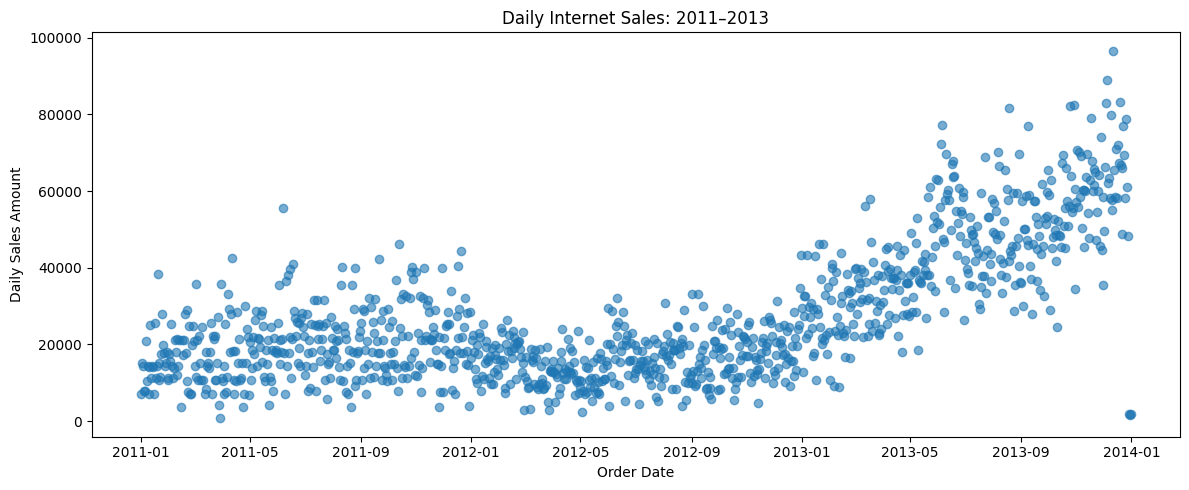

In [11]:
#plot daily sales
plt.figure(figsize=(12, 5))

plt.scatter(
    daily_sales['OrderDate'],
    daily_sales['SalesAmount'],
    alpha=0.6
)

plt.xlabel('Order Date')
plt.ylabel('Daily Sales Amount')
plt.title('Daily Internet Sales: 2011–2013')

plt.tight_layout()
plt.show()

According to the daily sales plotted above, there is a substantial day-to-day variation, but the overall pattern suggests an upward trend over time, particularly during 2013.

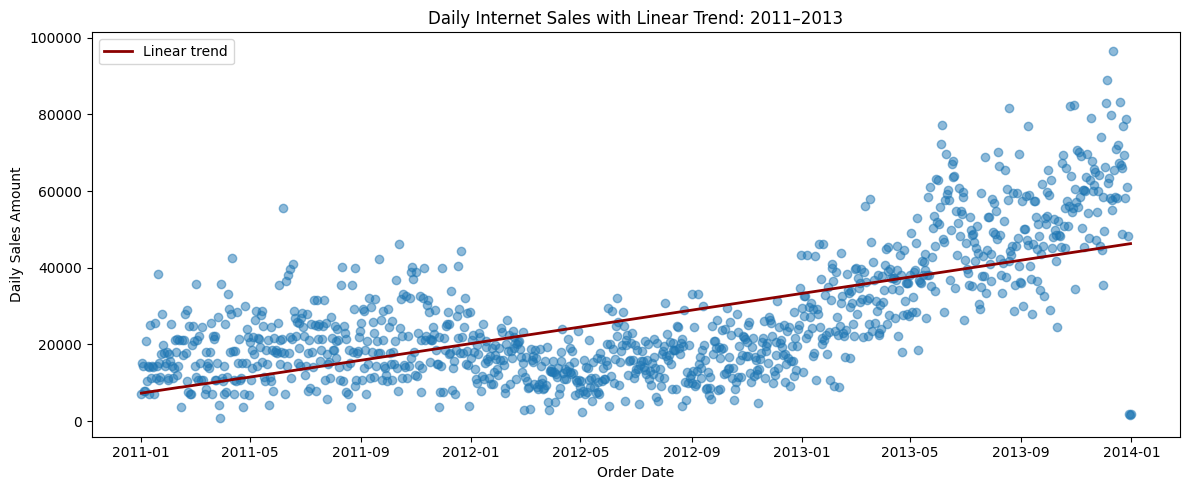

In [18]:
# Plot regression trend line
daily_sales['day_index'] = range(1, len(daily_sales) + 1)

# Fit a linear trend line
slope, intercept = np.polyfit(
    daily_sales['day_index'],
    daily_sales['SalesAmount'],
    1)

plt.figure(figsize=(12, 5))

plt.scatter(
    daily_sales['OrderDate'],
    daily_sales['SalesAmount'],
    alpha=0.5)

# draw the regression trend line on the existing scatter plot
plt.plot(
    daily_sales['OrderDate'],
    slope * daily_sales['day_index'] + intercept,
    color='darkred',
    linewidth=2,
    label='Linear trend')

plt.xlabel('Order Date')
plt.ylabel('Daily Sales Amount')
plt.title('Daily Internet Sales with Linear Trend: 2011–2013')
plt.legend()

plt.tight_layout()
plt.show()

In [19]:
# generate 5 years future dates
future_dates = pd.date_range(
    start='2014-01-01',
    end='2018-12-31',
    freq='D'
)

future_dates[:5], future_dates[-5:]

(DatetimeIndex(['2014-01-01', '2014-01-02', '2014-01-03', '2014-01-04',
                '2014-01-05'],
               dtype='datetime64[ns]', freq='D'),
 DatetimeIndex(['2018-12-27', '2018-12-28', '2018-12-29', '2018-12-30',
                '2018-12-31'],
               dtype='datetime64[ns]', freq='D'))

In [20]:
#add index
future_day_index = range(
    len(daily_sales) + 1,
    len(daily_sales) + len(future_dates) + 1
)

future_forecast = pd.DataFrame({
    'OrderDate': future_dates,
    'day_index': future_day_index
})

future_forecast.head()

,OrderDate,day_index
0,2014-01-01,1094
1,2014-01-02,1095
2,2014-01-03,1096
3,2014-01-04,1097
4,2014-01-05,1098


In [22]:
future_forecast['forecast_sales'] = (
    slope * future_forecast['day_index'] + intercept
)

future_forecast.head()

,OrderDate,day_index,forecast_sales
0,2014-01-01,1094,46315.956817
1,2014-01-02,1095,46351.673183
2,2014-01-03,1096,46387.389549
3,2014-01-04,1097,46423.105915
4,2014-01-05,1098,46458.822281


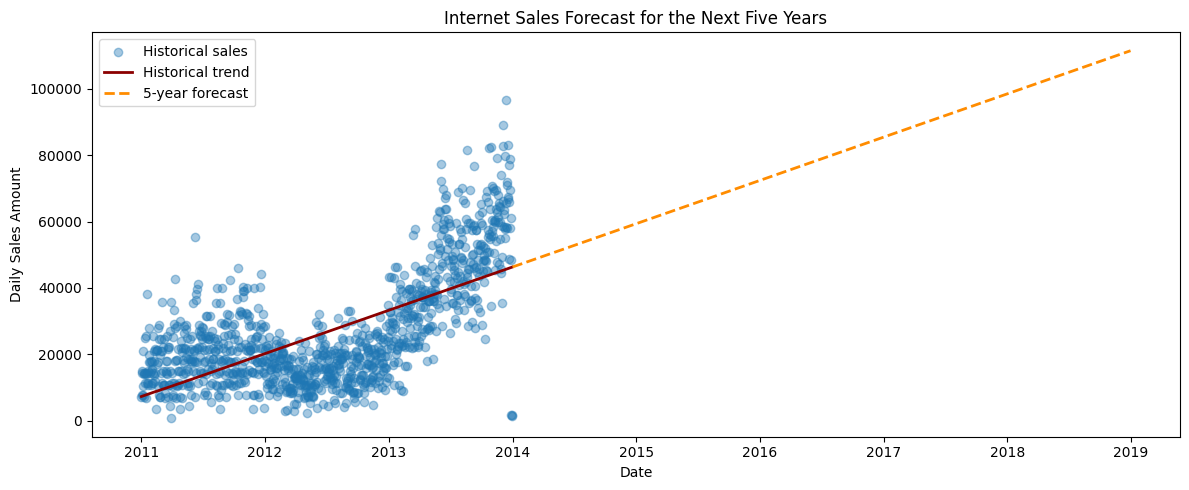

In [25]:
#the plot included both historical and future parts
plt.figure(figsize=(12, 5))

# Historical daily sales
plt.scatter(
    daily_sales['OrderDate'],
    daily_sales['SalesAmount'],
    alpha=0.4,
    label='Historical sales')

# Historical linear trend
plt.plot(
    daily_sales['OrderDate'],
    slope * daily_sales['day_index'] + intercept,
    linewidth=2,
    color='darkred',
    label='Historical trend')

# Five-year forecast
plt.plot(
    future_forecast['OrderDate'],
    future_forecast['forecast_sales'],
    color='darkorange',
    linestyle='--',
    linewidth=2,
    label='5-year forecast'
)

plt.xlabel('Date')
plt.ylabel('Daily Sales Amount')
plt.title('Internet Sales Forecast for the Next Five Years')
plt.legend()

plt.tight_layout()
plt.show()

In [27]:
#summarize statistics
product_sales = (
    df.groupby('EnglishProductName')['SalesAmount']
      .agg(['count', 'mean', 'sum'])
      .sort_values(by='sum', ascending=False)
)

product_sales.head()

,count,mean,sum
EnglishProductName,,,
"Mountain-200 Black, 46",620,2215.273465,1.373470e+06
"Mountain-200 Black, 42",614,2220.101129,1.363142e+06
"Mountain-200 Silver, 38",596,2247.420789,1.339463e+06
"Mountain-200 Silver, 46",580,2243.276032,1.301100e+06
"Mountain-200 Black, 38",582,2224.855913,1.294866e+06


According to the statistics, the historical 'SalesAmount' shows that the **"Mountain-200 Black, 46"** generated the highest sales thought 2021-2023.

Since we have a positive, increasing trend forecast for the future sales. It would be the strongest candidate to generate the most sales if the observed pattern continues.